In [28]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
DATA_PATH = '../../data'
MERGEGEN_RESULTS = '../../mergeGen/RESULTS'
SBCR_RESULTS = '../../sbcr'
ANALYSIS_PATH = '../../analysis'
INTERMEDIARY_RESULTS = f"{ANALYSIS_PATH}/intermediary_data"

MERGEGEN_DATASET2 = f"{MERGEGEN_RESULTS}/mergeGen_dataset2_CSharp_model_dataset2_CSharp_similarities.csv"
SBCR_DATASET2 = f"{SBCR_RESULTS}/rq2_CSharp/RESULTS/results_evaluate_dataset2_CSharp_combination_rq2_CSharp_seed-3022024.xlsx"

DATASET2_COMPLETE = f"{DATA_PATH}/dataset2_CSharp_complete.json" 
DATASET2_TESTING = f"{DATA_PATH}/dataset2_CSharp_testing.json"
DATASET2_METADATA = f"{DATA_PATH}/dataset2_CSharp_metadata.json"
DATASET2_STATS = f"{DATA_PATH}/dataset2_CSharp_complete_stats.csv"

MERGEGEN_BETTER = f"{INTERMEDIARY_RESULTS}/rq4_dataset2_CSharp_qualitative_list_MergegenBetter.csv"
SBCR_BETTER = f"{INTERMEDIARY_RESULTS}/rq4_dataset2_CSharp_qualitative_list_SBCRBetter.csv"

In [3]:
df_complete_ds2 = pd.read_json(DATASET2_COMPLETE)

In [4]:
df_test_ds2 = pd.read_json(DATASET2_TESTING)
df_test_ds2

,all_raw_base,all_raw_a,all_raw_b,all_raw_res,merge_id,chunk_number
0,if( !lbItems.IsEnabled )\n,\n lbItems.ItemsSource = _sys.Items;\...,\n if( !lbItems.IsEnabled ) \n,\n lbItems.ItemsSource = _sys.Items;\...,42525,8
1,using (var httpClient = new Servic...,using (var httpClient = new Servic...,\n using (var httpClient = new Json...,using (var httpClient = new JsonHt...,3742,1
2,var metadata = new Metadata {\...,var metadata = new Metadata {\...,\n var metadata = new Metadata\...,var metadata = new Metadata\n ...,72657,2
3,foreach (var sho in items) {\n va...,foreach (var sho in items) {\n va...,\n\t\t\tforeach (var sho in items) {\n\t\t\t\t...,foreach (var sho in items) {\n va...,85061,2
4,"\t\t\t\t\tDebugLocation(484, 28);\n","\t\t\t\t\tDebugLocation(490, 28);\n","\n\t\t\t\t\tDebugLocation(488, 28);\n","\t\t\t\t\tDebugLocation(494, 28);\n",68052,278
...,...,...,...,...,...,...
2065,this.deleteAllUntrackedFilesToolSt...,this.deleteAllUntrackedFilesToolSt...,\n this.deleteAllUntrackedFilesTool...,this.deleteAllUntrackedFilesToolSt...,52592,10
2066,﻿using System;\nusing System.Collections.Gener...,﻿using System;\nusing System.Collections.Gener...,\n﻿using System;\nusing System.Collections.Gen...,﻿using System;\nusing System.Collections.Gener...,76818,1
2067,// parameter locations\n ...,// parameter locations\n ...,\n,,63854,1
2068,"#line 204 ""C:\Dev\Repos\AWSDotNetP...","#line 204 ""C:\Users\costleya\Work\...","\n #line 228 ""C:\Dev\Repos\AWSDotNe...","#line 230 ""C:\Users\costleya\Work\...",46667,61


In [5]:
df_mergegen_ds2 = pd.read_csv(MERGEGEN_DATASET2)
data = []
for index, row in df_mergegen_ds2.iterrows():
    chunk = df_complete_ds2.iloc[row['chunk_index']]
    chunk_id = f"{chunk['merge_id']}-{chunk['chunk_number']}"
    data.append(chunk_id)
df_mergegen_ds2['chunk_id'] = data
df_mergegen_ds2 = df_mergegen_ds2.rename(columns={"complete_similarity": "sim_mergegen", "time": "time_mergegen", "similarity":"sim_mergegen_trunc", "parents_similarity":"mergegen_parents_sim"})
df_mergegen_ds2

,chunk_index,sim_mergegen_trunc,sim_mergegen,time_mergegen,v1_similarity,v2_similarity,mergegen_parents_sim,result,chunk_id
0,11446,0.890909,0.884615,0.278662,0.649351,1.000000,0.824675,FAIL,86686-1
1,18748,0.992537,0.992063,0.331669,1.000000,0.634921,0.817460,FAIL,78151-14
2,8935,0.853333,0.283531,1.341049,0.221239,0.290155,0.255697,FAIL,71211-1
3,2518,0.616162,0.622951,0.138654,0.615385,0.622951,0.619168,FAIL,29420-6
4,12021,0.581395,0.550000,0.099027,0.688525,0.644068,0.666296,FAIL,86841-1
...,...,...,...,...,...,...,...,...,...
2065,17894,1.000000,1.000000,0.092459,0.433213,0.956522,0.694867,SUCCEED,62386-1
2066,17318,1.000000,1.000000,0.385109,0.854237,1.000000,0.927119,SUCCEED,18039-20
2067,2351,0.641004,0.881188,1.341271,0.881188,0.881188,0.881188,SUCCEED,74349-2
2068,6790,1.000000,1.000000,0.073513,0.500000,1.000000,0.750000,SUCCEED,29925-32


In [6]:
df_mergegen_ds2.describe()

,chunk_index,sim_mergegen_trunc,sim_mergegen,time_mergegen,v1_similarity,v2_similarity,mergegen_parents_sim
count,2070.000000,2070.000000,2070.000000,2070.000000,2070.000000,2070.000000,2070.000000
mean,10368.984058,0.889966,0.878201,0.413602,0.703149,0.726593,0.714871
std,5880.124748,0.221988,0.250110,0.420956,0.298172,0.313186,0.204303
min,4.000000,0.000000,0.000000,0.026307,0.000000,0.000000,0.000000
25%,5228.250000,0.894737,0.911673,0.125672,0.500000,0.585774,0.597028
50%,10471.500000,1.000000,1.000000,0.238338,0.805970,0.857143,0.750000
75%,15429.250000,1.000000,1.000000,0.492938,0.959391,0.976526,0.884675
max,20669.000000,1.000000,1.000000,1.751323,1.000000,1.000000,1.000000


In [7]:
df_sbcr_ds2 = pd.read_excel(SBCR_DATASET2)
df_sbcr_ds2 = df_sbcr_ds2.rename(columns={"solution_sim_lcs": "sim_sbcr", "time_seconds": "time_sbcr", "fitness": "fitness_sbcr"})
df_sbcr_ds2.sort_values('chunk_id')

,chunk_id,fitness_sbcr,sim_sbcr,status,time_sbcr
435,10210-1,0.808369,0.601227,ok,0.800327
302,10219-1,0.921245,0.922620,ok,41.749195
191,10284-1,0.750221,1.000000,ok,0.423213
26,10624-7,0.859403,0.719697,ok,0.156138
13,11555-2,0.826943,0.988235,ok,0.055722
...,...,...,...,...,...
23,94678-1,0.864443,0.978022,ok,0.057789
86,94759-7,0.809379,0.883721,ok,0.035529
38,9589-1,NaN,NaN,OUT_OF_LIMITS,NaN
378,9869-1,0.856779,0.756098,ok,0.206199


In [8]:
df_results_ds2 = df_sbcr_ds2[['chunk_id', 'fitness_sbcr', 'sim_sbcr', 'time_sbcr']].merge(df_mergegen_ds2[['chunk_index', 'chunk_id', 'sim_mergegen', 'time_mergegen', 'mergegen_parents_sim']], on='chunk_id', suffixes=('_sbcr', '_mergegen'))
df_results_ds2

,chunk_id,fitness_sbcr,sim_sbcr,time_sbcr,chunk_index,sim_mergegen,time_mergegen,mergegen_parents_sim
0,25742-20,0.781075,0.888532,1.353024,12203,0.849730,1.327415,0.759161
1,84068-17,0.934575,1.000000,0.059129,8036,1.000000,0.192046,0.940322
2,35805-2,0.909859,0.926136,0.074013,14767,1.000000,0.218890,0.914904
3,56487-2,0.992278,0.988235,0.108419,1360,1.000000,0.238006,0.992281
4,40408-4,0.789696,1.000000,0.741853,10956,1.000000,0.212470,0.818086
...,...,...,...,...,...,...,...,...
619,74717-1,0.876398,0.948746,0.303706,2833,0.998514,0.676723,0.955833
620,55850-37,0.760039,1.000000,1.892880,16877,1.000000,0.105346,0.741462
621,32210-1,0.740242,0.680486,48.694607,16031,0.303150,1.338662,0.305750
622,94084-4,0.856539,0.847059,0.065524,16753,1.000000,0.197893,0.869830


In [9]:
print(df_results_ds2['sim_sbcr'].isnull().sum()) 
df_results_clean = df_results_ds2.dropna(subset=['sim_sbcr', 'sim_mergegen'])

15


In [10]:
print(df_results_clean[['sim_sbcr', 'sim_mergegen', 'time_sbcr', 'time_mergegen']].describe())

         sim_sbcr  sim_mergegen   time_sbcr  time_mergegen
count  609.000000    609.000000  609.000000     609.000000
mean     0.798304      0.886548    2.569335       0.455235
std      0.244752      0.226261   10.800010       0.410311
min      0.006964      0.000000    0.027724       0.039480
25%      0.680578      0.910615    0.080309       0.171762
50%      0.894879      1.000000    0.154441       0.277324
75%      1.000000      1.000000    0.673870       0.559484
max      1.000000      1.000000  129.911749       1.614337


In [11]:
df_results_clean['diff'] = df_results_clean['sim_sbcr'] - df_results_clean['sim_mergegen']
df_results_clean

/tmp/ipykernel_15335/520408852.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_results_clean['diff'] = df_results_clean['sim_sbcr'] - df_results_clean['sim_mergegen']


,chunk_id,fitness_sbcr,sim_sbcr,time_sbcr,chunk_index,sim_mergegen,time_mergegen,mergegen_parents_sim,diff
0,25742-20,0.781075,0.888532,1.353024,12203,0.849730,1.327415,0.759161,0.038803
1,84068-17,0.934575,1.000000,0.059129,8036,1.000000,0.192046,0.940322,0.000000
2,35805-2,0.909859,0.926136,0.074013,14767,1.000000,0.218890,0.914904,-0.073864
3,56487-2,0.992278,0.988235,0.108419,1360,1.000000,0.238006,0.992281,-0.011765
4,40408-4,0.789696,1.000000,0.741853,10956,1.000000,0.212470,0.818086,0.000000
...,...,...,...,...,...,...,...,...,...
619,74717-1,0.876398,0.948746,0.303706,2833,0.998514,0.676723,0.955833,-0.049768
620,55850-37,0.760039,1.000000,1.892880,16877,1.000000,0.105346,0.741462,0.000000
621,32210-1,0.740242,0.680486,48.694607,16031,0.303150,1.338662,0.305750,0.377336
622,94084-4,0.856539,0.847059,0.065524,16753,1.000000,0.197893,0.869830,-0.152941


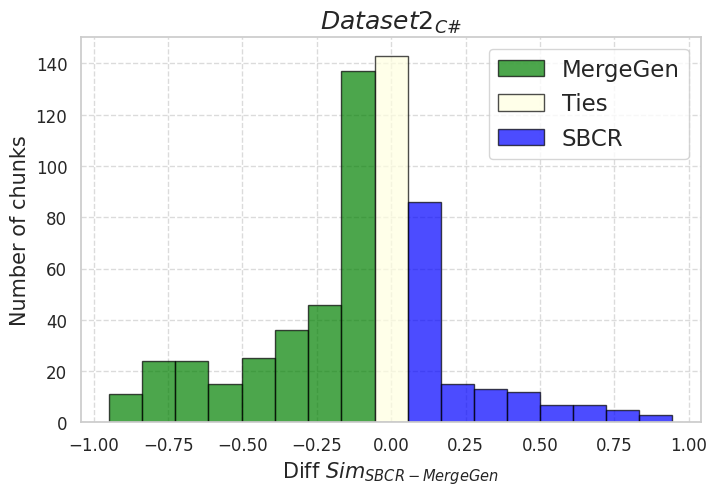

In [35]:
sns.set(style="whitegrid")
sns.set_context("notebook", font_scale=1.5)

# Get the 'diff' data from the DataFrame
data = df_results_clean['diff']

# Split the data into three groups:
# - left_data: values less than 0
# - center_data: values equal to 0
# - right_data: values greater than 0
left_data   = data[data < 0]
center_data = data[data == 0]
right_data  = data[data > 0]

# Define the number of bins for the left and right groups
n_bins_left  = 8
n_bins_right = 8

# Create bins for the left side covering the entire range of negative values
left_bins = np.linspace(left_data.min(), 0, n_bins_left + 1)
# Create bins for the right side covering the entire range of positive values
right_bins = np.linspace(0, right_data.max(), n_bins_right + 1)

# Compute histogram counts for left and right data
left_counts, _  = np.histogram(left_data, bins=left_bins)
right_counts, _ = np.histogram(right_data, bins=right_bins)

# Calculate the original centers and widths of the bins
left_centers_orig  = (left_bins[:-1] + left_bins[1:]) / 2
right_centers_orig = (right_bins[:-1] + right_bins[1:]) / 2
left_widths  = np.diff(left_bins)
right_widths = np.diff(right_bins)

# Set the central bin's width as the average of the last left bin's width and the first right bin's width
central_width = (left_widths[-1] + right_widths[0]) / 2

# For a visual gap, shift the left centers to the left by central_width/2 and the right centers to the right by central_width/2.
# This moves the left bars so that their rightmost edge becomes -central_width/2,
# and the right bars so that their leftmost edge becomes +central_width/2.
left_centers  = left_centers_orig - central_width/2
right_centers = right_centers_orig + central_width/2

# Count the number of values that are exactly 0 (for the center bin)
center_count = len(center_data)

# Plot the histogram
plt.figure(figsize=(8, 5))

# Plot the left bars (values < 0)
plt.bar(left_centers, left_counts, width=left_widths,
        color='green', edgecolor='black', alpha=0.7, label="MergeGen")

# Plot the center bar (values == 0) at x = 0 with the computed central_width
plt.bar(0, center_count, width=central_width,
        color='lightyellow', edgecolor='black', alpha=0.7, label="Ties")

# Plot the right bars (values > 0)
plt.bar(right_centers, right_counts, width=right_widths,
        color='blue', edgecolor='black', alpha=0.7, label="SBCR")

# Final plot configurations
plt.title('$Dataset2_{C\#}$')
plt.xlabel('Diff $Sim_{SBCR-MergeGen}$', fontsize=15)
plt.ylabel('Number of chunks', fontsize=15)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()

plt.show()

In [30]:
print(len(df_results_clean))
print(center_count)
print(left_counts)
print(right_counts)
print(center_count + left_counts.sum() + right_counts.sum())
print(center_count, left_counts.sum(), right_counts.sum())
print(len(left_data) + len(center_data) + len(right_data))

609
143
[ 11  24  24  15  25  36  46 137]
[86 15 13 12  7  7  5  3]
609
143 318 148
609


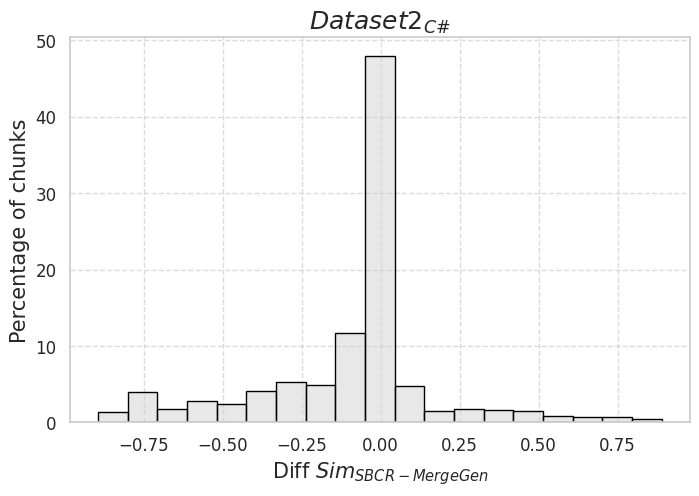

In [12]:
# close to 1 = sbcr is better
# close to -1 = mergegen is better
sns.set(style="whitegrid")
sns.set_context("notebook", font_scale=1.5)
bins = 19
plt.figure(figsize=(8, 5))
ax = sns.histplot(df_results_clean['diff'], bins=bins, stat='percent',color='lightgray', label="$Dataset1$", edgecolor='black', alpha=0.5)
# ax = sns.histplot(dataset2_Java['diff'], bins=bins, stat='percent', color='blue', label="$Dataset2_{Java}$", edgecolor='black', alpha=0.5)

plt.title('$Dataset2_{C\#}$')
plt.xlabel('Diff $Sim_{SBCR-MergeGen}$', fontsize=15)
plt.ylabel('Percentage of chunks', fontsize=15)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.grid(True, linestyle='--', alpha=0.7)
# plt.xlim(-40,40)
# plt.legend()
plt.show()

In [13]:
df_stats = pd.read_csv(DATASET2_STATS)
df = df_results_clean.merge(df_stats, on='chunk_id')
df['diff_chunk_solution'] = df['chunk_size_char'] - df['solution_size_char']
df['chunk_diff_lines'] = df['v1_size'] - df['v2_size']
df['v1_size_rel'] = df['v1_size']/(df['v1_size'] + df['v2_size'])
df['v2_size_rel'] = df['v2_size']/(df['v1_size'] + df['v2_size'])
df['chunk_diff_lines_rel'] = df['v1_size_rel'] - df['v2_size_rel']
df['chunk_diff_char'] = df['v1_size_char'] - df['v2_size_char']
df['v1_size_char_rel'] = df['v1_size_char']/(df['v1_size_char'] + df['v2_size_char'])
df['v2_size_char_rel'] = df['v2_size_char']/(df['v1_size_char'] + df['v2_size_char'])
df['chunk_diff_char_rel'] = df['v1_size_char_rel'] - df['v2_size_char_rel']
df

,chunk_id,fitness_sbcr,sim_sbcr,time_sbcr,chunk_index,sim_mergegen,time_mergegen,mergegen_parents_sim,diff,chunk_size,...,resolution_parents_sim,diff_chunk_solution,chunk_diff_lines,v1_size_rel,v2_size_rel,chunk_diff_lines_rel,chunk_diff_char,v1_size_char_rel,v2_size_char_rel,chunk_diff_char_rel
0,25742-20,0.781075,0.888532,1.353024,12203,0.849730,1.327415,0.759161,0.038803,19,...,0.780153,595,-1,0.473684,0.526316,-0.052632,-42,0.482587,0.517413,-0.034826
1,84068-17,0.934575,1.000000,0.059129,8036,1.000000,0.192046,0.940322,0.000000,4,...,0.934575,112,0,0.500000,0.500000,0.000000,32,0.562016,0.437984,0.124031
2,35805-2,0.909859,0.926136,0.074013,14767,1.000000,0.218890,0.914904,-0.073864,8,...,0.924561,160,-2,0.375000,0.625000,-0.250000,-13,0.480122,0.519878,-0.039755
3,56487-2,0.992278,0.988235,0.108419,1360,1.000000,0.238006,0.992281,-0.011765,5,...,0.992218,130,-1,0.400000,0.600000,-0.200000,-2,0.496124,0.503876,-0.007752
4,40408-4,0.789696,1.000000,0.741853,10956,1.000000,0.212470,0.818086,0.000000,6,...,0.789418,71,-4,0.166667,0.833333,-0.666667,-96,0.308000,0.692000,-0.384000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
604,74717-1,0.876398,0.948746,0.303706,2833,0.998514,0.676723,0.955833,-0.049768,19,...,0.912816,353,-3,0.421053,0.578947,-0.157895,-103,0.434728,0.565272,-0.130545
605,55850-37,0.760039,1.000000,1.892880,16877,1.000000,0.105346,0.741462,0.000000,4,...,0.759303,52,-2,0.250000,0.750000,-0.500000,-38,0.338983,0.661017,-0.322034
606,32210-1,0.740242,0.680486,48.694607,16031,0.303150,1.338662,0.305750,0.377336,310,...,0.837907,4182,10,0.516129,0.483871,0.032258,-571,0.473350,0.526650,-0.053300
607,94084-4,0.856539,0.847059,0.065524,16753,1.000000,0.197893,0.869830,-0.152941,5,...,0.813693,75,-1,0.400000,0.600000,-0.200000,-24,0.455556,0.544444,-0.088889


In [14]:
# cases where mergeGen is better
print(len(df[df['diff'] < 0]))
df.sort_values('diff').to_csv(MERGEGEN_BETTER)
df.sort_values('diff').head(20)


318


,chunk_id,fitness_sbcr,sim_sbcr,time_sbcr,chunk_index,sim_mergegen,time_mergegen,mergegen_parents_sim,diff,chunk_size,...,resolution_parents_sim,diff_chunk_solution,chunk_diff_lines,v1_size_rel,v2_size_rel,chunk_diff_lines_rel,chunk_diff_char,v1_size_char_rel,v2_size_char_rel,chunk_diff_char_rel
370,28965-1,0.508324,0.105919,0.448779,13696,1.000000,0.072970,0.298799,-0.894081,42,...,0.300823,891,-40,0.023810,0.976190,-0.952381,-904,0.021186,0.978814,-0.957627
169,44668-1,0.562533,0.142636,0.139272,10723,1.000000,0.759387,0.577157,-0.857364,17,...,0.567419,50,13,0.882353,0.117647,0.764706,554,0.926154,0.073846,0.852308
181,61947-4,0.577609,0.157534,0.220688,4572,1.000000,0.113149,0.512795,-0.842466,10,...,0.557494,526,-8,0.100000,0.900000,-0.800000,-469,0.090750,0.909250,-0.818499
379,36509-2,0.504644,0.162791,0.073505,8710,1.000000,0.261723,0.081250,-0.837209,7,...,0.148707,145,5,0.857143,0.142857,0.714286,158,0.993750,0.006250,0.987500
107,18817-1,0.542300,0.167017,0.930327,20222,1.000000,0.183860,0.448429,-0.832983,44,...,0.451954,1775,-40,0.045455,0.954545,-0.909091,-1730,0.053202,0.946798,-0.893595
165,14172-11,0.562961,0.193548,0.305524,11418,1.000000,1.168013,0.564124,-0.806452,13,...,0.558594,136,-11,0.076923,0.923077,-0.846154,-609,0.080000,0.920000,-0.840000
293,14205-4,0.582058,0.194726,0.798264,8462,1.000000,0.772657,0.566531,-0.805274,13,...,0.558784,127,-11,0.076923,0.923077,-0.846154,-475,0.085515,0.914485,-0.828970
221,14145-4,0.585714,0.198934,0.282651,20640,1.000000,0.924701,0.573043,-0.801066,13,...,0.565236,135,-11,0.076923,0.923077,-0.846154,-529,0.088647,0.911353,-0.822706
115,73130-2,0.708928,0.208651,0.374571,2305,1.000000,0.086252,0.318039,-0.791349,7,...,0.386523,402,-3,0.285714,0.714286,-0.428571,-196,0.282222,0.717778,-0.435556
320,14167-2,0.591166,0.209983,0.321735,15419,1.000000,0.887533,0.580216,-0.790017,13,...,0.571525,140,-11,0.076923,0.923077,-0.846154,-537,0.093797,0.906203,-0.812405


In [15]:
# cases where sbcr is better
print(len(df[df['diff'] > 0]))
df.sort_values('diff', ascending=False).to_csv(SBCR_BETTER)
df.sort_values('diff', ascending=False).head(20)

148


,chunk_id,fitness_sbcr,sim_sbcr,time_sbcr,chunk_index,sim_mergegen,time_mergegen,mergegen_parents_sim,diff,chunk_size,...,resolution_parents_sim,diff_chunk_solution,chunk_diff_lines,v1_size_rel,v2_size_rel,chunk_diff_lines_rel,chunk_diff_char,v1_size_char_rel,v2_size_char_rel,chunk_diff_char_rel
532,42525-8,0.491027,0.940826,40.289713,7992,0.051498,0.420031,0.149946,0.889328,297,...,0.489465,533,293,0.993266,0.006734,0.986532,8376,0.995621,0.004379,0.991243
472,33411-1,0.500486,0.824813,0.434198,17963,0.000000,1.302907,0.500000,0.824813,22,...,0.413856,307,20,0.954545,0.045455,0.909091,1026,0.999027,0.000973,0.998054
244,7795-1,0.481715,0.806730,0.834221,7714,0.000000,0.869428,0.500000,0.806730,25,...,0.427206,335,-25,0.000000,1.000000,-1.000000,-1318,0.000000,1.000000,-1.000000
419,43331-1,0.872003,0.880238,64.084488,2157,0.123806,1.345857,0.128685,0.756431,1090,...,0.969681,16351,-32,0.485321,0.514679,-0.029358,-1231,0.482028,0.517972,-0.035945
66,85649-1,0.769216,0.833957,48.378678,1675,0.116647,1.338900,0.130167,0.717310,550,...,0.927427,8214,-86,0.421818,0.578182,-0.156364,-2062,0.444330,0.555670,-0.111339
482,24624-1,0.779737,0.781667,70.335769,19176,0.064825,1.350094,0.069145,0.716842,699,...,0.941063,13439,-7,0.494993,0.505007,-0.010014,-788,0.486418,0.513582,-0.027163
294,10219-1,0.921245,0.922620,41.749195,1668,0.216523,1.341462,0.209174,0.706097,291,...,0.985479,3542,-1,0.498282,0.501718,-0.003436,74,0.505155,0.494845,0.010309
218,90099-1,0.815632,0.814871,57.483275,8583,0.131014,1.344113,0.125128,0.683857,675,...,0.997060,12739,-1,0.499259,0.500741,-0.001481,42,0.500823,0.499177,0.001646
520,36229-1,0.693139,0.764621,129.911749,5235,0.135089,1.341730,0.126720,0.629532,946,...,0.850183,17121,-44,0.476744,0.523256,-0.046512,-1428,0.478125,0.521875,-0.043750
558,84019-2,0.499392,0.625210,0.572839,4461,0.000000,0.233715,0.500000,0.625210,4,...,0.312187,225,-4,0.000000,1.000000,-1.000000,-412,0.000000,1.000000,-1.000000


In [16]:
df_mergegen = df[df['diff'] < 0]
df_sbcr = df[df['diff'] > 0]

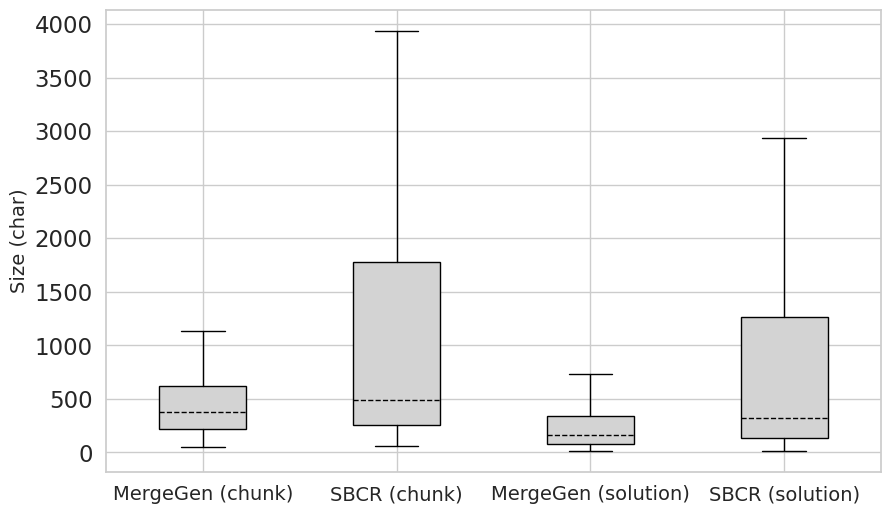

In [17]:
# Create a boxplot
plt.figure(figsize=(10, 6))  # Set the figure size
plt.boxplot([df_mergegen['chunk_size_char'], df_sbcr['chunk_size_char'], df_mergegen['solution_size_char'], df_sbcr['solution_size_char']], 
            patch_artist=True,  # To fill the box with color
#             widths=0.5,  # Width of the box
            medianprops=dict(color='black', linestyle='--'),  # Color of the median line
            boxprops=dict(facecolor='lightgray', color='black'),  # Color of the box
            whiskerprops=dict(color='black'),  # Color of the whiskers
            capprops=dict(color='black'),  # Color of the caps
            showfliers=False)  # Properties of the outliers

# Customize labels and title
# plt.xlabel('Your X Label')
plt.ylabel('Size (char)', fontsize=14)
plt.xticks([1, 2, 3, 4], ['MergeGen (chunk)', 'SBCR (chunk)', 'MergeGen (solution)', 'SBCR (solution)'], fontsize=14)
# plt.title('Similarity between random candidates and parents \n using each aggregation function', fontsize=16)

# Save or show the plot
# plt.savefig('RQ3_boxplots.png', dpi=300)  # Save the plot as a PNG file with higher resolution
plt.show()  # Show the plot

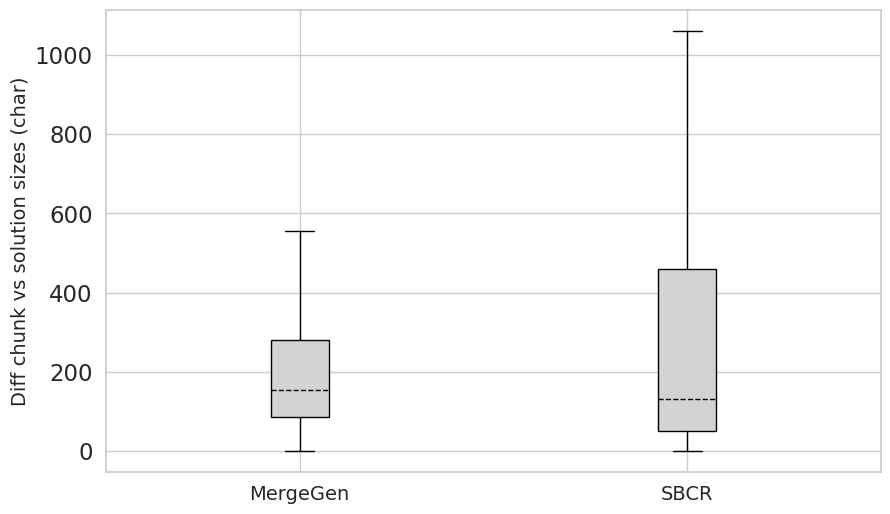

In [18]:
plt.figure(figsize=(10, 6))  # Set the figure size
plt.boxplot([df_mergegen['diff_chunk_solution'], df_sbcr['diff_chunk_solution']], 
            patch_artist=True,  # To fill the box with color
#             widths=0.5,  # Width of the box
            medianprops=dict(color='black', linestyle='--'),  # Color of the median line
            boxprops=dict(facecolor='lightgray', color='black'),  # Color of the box
            whiskerprops=dict(color='black'),  # Color of the whiskers
            capprops=dict(color='black'),  # Color of the caps
            showfliers=False)  # Properties of the outliers

plt.ylabel('Diff chunk vs solution sizes (char)', fontsize=14)
plt.xticks([1, 2], ['MergeGen', 'SBCR'], fontsize=14)

plt.show()  # Show the plot

In [19]:
print(df_mergegen[['fitness_sbcr','diff_chunk_solution']].describe())
print(df_sbcr[['fitness_sbcr','diff_chunk_solution']].describe())
            

       fitness_sbcr  diff_chunk_solution
count    318.000000           318.000000
mean       0.750480           339.257862
std        0.142336          1185.659567
min        0.390215             1.000000
25%        0.654181            86.250000
50%        0.755403           155.000000
75%        0.864217           279.750000
max        0.992278         17226.000000
       fitness_sbcr  diff_chunk_solution
count    148.000000           148.000000
mean       0.756338          1236.533784
std        0.138033          3045.510548
min        0.481715             1.000000
25%        0.666272            51.750000
50%        0.781555           131.000000
75%        0.853659           460.250000
max        0.985927         17121.000000


In [20]:
df['fitness_to_solution_diff'] = df['mergegen_parents_sim'] - df['fitness_sbcr']

In [21]:
df[(df['diff'] < 0) & (df['mergegen_parents_sim'] > df['fitness_sbcr'])].sort_values('fitness_to_solution_diff', ascending=False)

,chunk_id,fitness_sbcr,sim_sbcr,time_sbcr,chunk_index,sim_mergegen,time_mergegen,mergegen_parents_sim,diff,chunk_size,...,diff_chunk_solution,chunk_diff_lines,v1_size_rel,v2_size_rel,chunk_diff_lines_rel,chunk_diff_char,v1_size_char_rel,v2_size_char_rel,chunk_diff_char_rel,fitness_to_solution_diff
155,86609-1,0.759636,0.637363,0.096595,11690,1.000000,0.104968,0.982753,-0.362637,8,...,112,4,0.750000,0.250000,0.500000,79,0.730994,0.269006,0.461988,0.223118
400,35958-1,0.704905,0.421308,0.082027,14120,1.000000,0.311510,0.808349,-0.578692,10,...,88,6,0.800000,0.200000,0.600000,237,0.785542,0.214458,0.571084,0.103445
414,30407-47,0.834008,0.936833,0.260348,5953,1.000000,0.598804,0.935684,-0.063167,13,...,337,-1,0.461538,0.538462,-0.076923,53,0.528773,0.471227,0.057546,0.101676
318,87700-2,0.591311,0.193487,0.363422,4421,0.920863,0.563603,0.689628,-0.727377,22,...,81,18,0.909091,0.090909,0.818182,819,0.899512,0.100488,0.799024,0.098317
242,89891-1,0.719619,0.444023,0.142497,20234,0.973568,0.391268,0.804621,-0.529546,12,...,125,-8,0.166667,0.833333,-0.666667,-286,0.230189,0.769811,-0.539623,0.085002
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,27362-1,0.605747,0.345979,0.231514,2693,0.972028,0.558626,0.607297,-0.626049,27,...,148,-21,0.111111,0.888889,-0.777778,-426,0.177273,0.822727,-0.645455,0.001550
165,14172-11,0.562961,0.193548,0.305524,11418,1.000000,1.168013,0.564124,-0.806452,13,...,136,-11,0.076923,0.923077,-0.846154,-609,0.080000,0.920000,-0.840000,0.001163
220,52644-1,0.911091,0.980892,0.078888,7485,1.000000,0.266331,0.911687,-0.019108,5,...,216,-1,0.400000,0.600000,-0.200000,-67,0.411141,0.588859,-0.177719,0.000597
97,71199-13,0.874229,0.844937,0.221822,4932,1.000000,0.434267,0.874802,-0.155063,12,...,293,0,0.500000,0.500000,0.000000,24,0.519737,0.480263,0.039474,0.000572


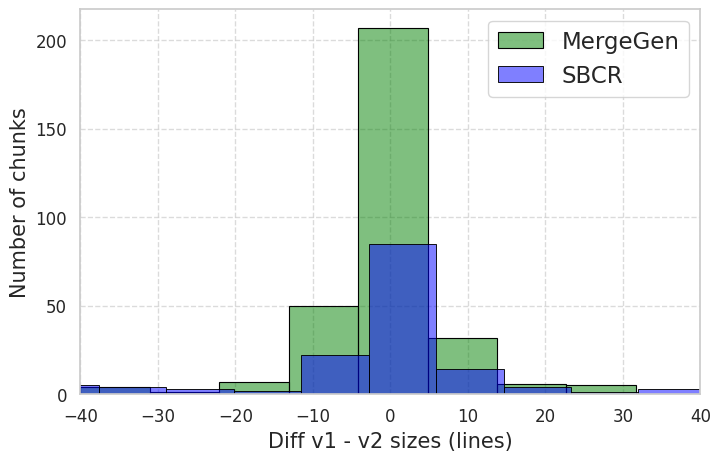

In [22]:
sns.set(style="whitegrid")
sns.set_context("notebook", font_scale=1.5)

plt.figure(figsize=(8, 5))
ax = sns.histplot(df_mergegen['chunk_diff_lines'], bins=50, color='green', label="MergeGen", edgecolor='black', alpha=0.5)
ax = sns.histplot(df_sbcr['chunk_diff_lines'],bins=50, color='blue', label="SBCR", edgecolor='black', alpha=0.5)

plt.xlabel('Diff v1 - v2 sizes (lines)', fontsize=15)
plt.ylabel('Number of chunks', fontsize=15)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.grid(True, linestyle='--', alpha=0.7)
plt.xlim(-40,40)
plt.legend()
plt.show()

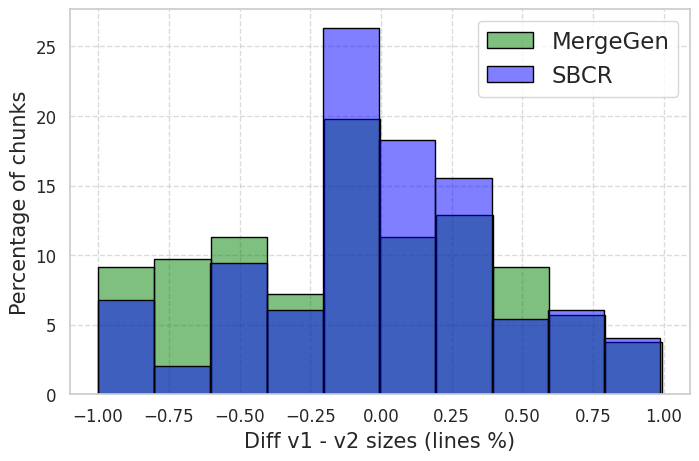

In [23]:
sns.set(style="whitegrid")
sns.set_context("notebook", font_scale=1.5)

plt.figure(figsize=(8, 5))
ax = sns.histplot(df_mergegen['chunk_diff_lines_rel'], stat='percent',color='green', label="MergeGen", edgecolor='black', alpha=0.5)
ax = sns.histplot(df_sbcr['chunk_diff_lines_rel'], stat='percent', color='blue', label="SBCR", edgecolor='black', alpha=0.5)

plt.xlabel('Diff v1 - v2 sizes (lines %)', fontsize=15)
plt.ylabel('Percentage of chunks', fontsize=15)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.grid(True, linestyle='--', alpha=0.7)
# plt.xlim(-40,40)
plt.legend()
plt.show()

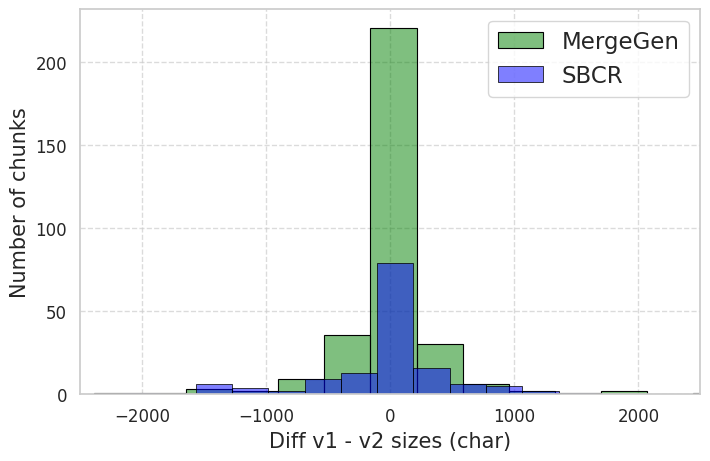

In [24]:
sns.set(style="whitegrid")
sns.set_context("notebook", font_scale=1.5)

plt.figure(figsize=(8, 5))
ax = sns.histplot(df_mergegen['chunk_diff_char'], bins=50, color='green', label="MergeGen", edgecolor='black', alpha=0.5)
ax = sns.histplot(df_sbcr['chunk_diff_char'],bins=50, color='blue', label="SBCR", edgecolor='black', alpha=0.5)

plt.xlabel('Diff v1 - v2 sizes (char)', fontsize=15)
plt.ylabel('Number of chunks', fontsize=15)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.grid(True, linestyle='--', alpha=0.7)
plt.xlim(-2500,2500)
plt.legend()
plt.show()

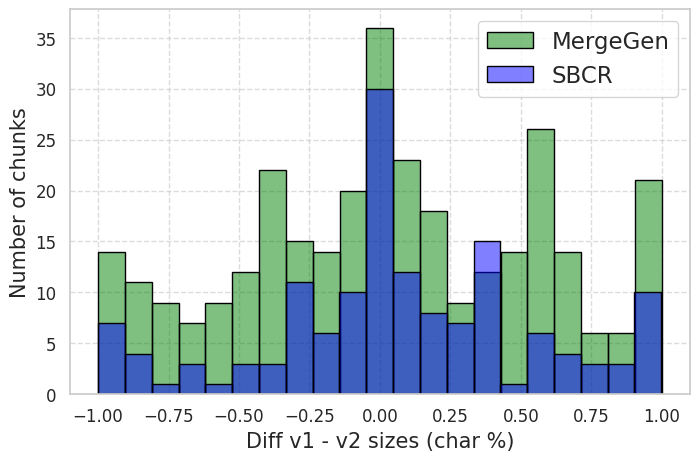

In [25]:
sns.set(style="whitegrid")
sns.set_context("notebook", font_scale=1.5)

plt.figure(figsize=(8, 5))
ax = sns.histplot(df_mergegen['chunk_diff_char_rel'], bins=21, color='green', label="MergeGen", edgecolor='black', alpha=0.5)
ax = sns.histplot(df_sbcr['chunk_diff_char_rel'], bins=21, color='blue', label="SBCR", edgecolor='black', alpha=0.5)

plt.xlabel('Diff v1 - v2 sizes (char %)', fontsize=15)
plt.ylabel('Number of chunks', fontsize=15)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.grid(True, linestyle='--', alpha=0.7)
# plt.xlim(-40,40)
plt.legend()
plt.show()

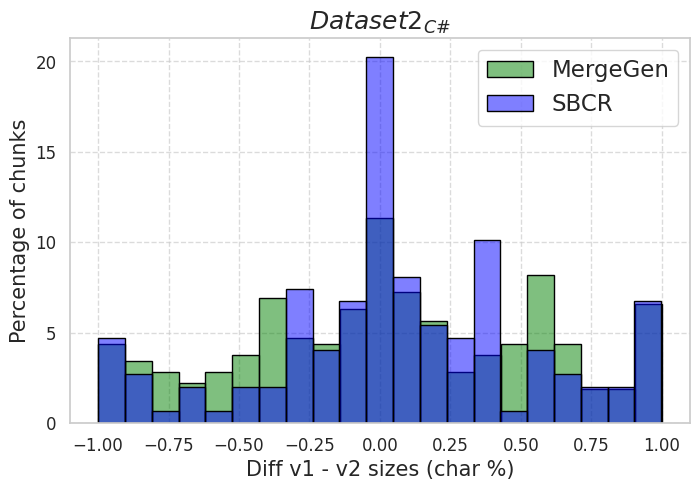

In [26]:
sns.set(style="whitegrid")
sns.set_context("notebook", font_scale=1.5)

plt.figure(figsize=(8, 5))
ax = sns.histplot(df_mergegen['chunk_diff_char_rel'], bins=21, stat='percent',color='green', label="MergeGen", edgecolor='black', alpha=0.5)
ax = sns.histplot(df_sbcr['chunk_diff_char_rel'], bins=21, stat='percent', color='blue', label="SBCR", edgecolor='black', alpha=0.5)

plt.title('$Dataset2_{C\#}$')
plt.xlabel('Diff v1 - v2 sizes (char %)', fontsize=15)
plt.ylabel('Percentage of chunks', fontsize=15)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.grid(True, linestyle='--', alpha=0.7)
# plt.xlim(-40,40)
plt.legend()
plt.show()

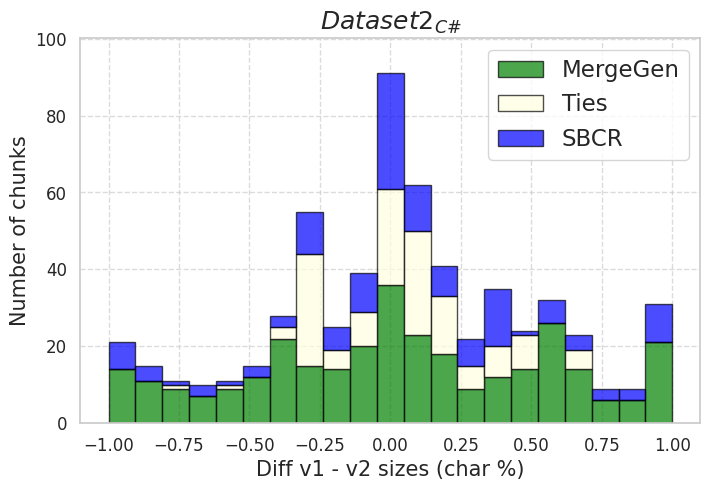

In [34]:
df_tie = df[df['diff'] == 0]

# Configuração do estilo
sns.set(style="whitegrid")
sns.set_context("notebook", font_scale=1.5)

# Definir bins comuns para ambos os conjuntos de dados
bins = np.linspace(min(df_mergegen['chunk_diff_char_rel'].min(), df_sbcr['chunk_diff_char_rel'].min(), df_tie['chunk_diff_char_rel'].min()),
                   max(df_mergegen['chunk_diff_char_rel'].max(), df_sbcr['chunk_diff_char_rel'].max(), df_tie['chunk_diff_char_rel'].max()), 22)

# Contar a frequência de cada abordagem nos bins
hist_mergegen, _ = np.histogram(df_mergegen['chunk_diff_char_rel'], bins=bins)
hist_sbcr, _ = np.histogram(df_sbcr['chunk_diff_char_rel'], bins=bins)
hist_tie, _ = np.histogram(df_tie['chunk_diff_char_rel'], bins=bins)


# # Normalizar para obter a porcentagem individual dentro de cada categoria
# hist_mergegen = (hist_mergegen / hist_mergegen.sum()) * 100
# hist_sbcr = (hist_sbcr / hist_sbcr.sum()) * 100

# Posições centrais dos bins
bin_centers = (bins[:-1] + bins[1:]) / 2

# Criar stacked bar plot
plt.figure(figsize=(8, 5))


plt.bar(bin_centers, hist_mergegen, width=np.diff(bins), color='green', edgecolor='black', label="MergeGen", alpha=0.7)
plt.bar(bin_centers, hist_tie, width=np.diff(bins), color='lightyellow', edgecolor='black', label="Ties", alpha=0.7, bottom=hist_mergegen)
plt.bar(bin_centers, hist_sbcr, width=np.diff(bins), color='blue', edgecolor='black', label="SBCR", alpha=0.7, bottom=hist_mergegen+hist_tie)


# Ajuste do eixo Y
max_y = (hist_mergegen + hist_sbcr + hist_tie).max()  # Valor máximo das barras empilhadas
plt.ylim(0, max_y * 1.1)  # Adiciona 10% de margem superior para melhor visualização

# Rótulos e título
plt.title('$Dataset2_{C\#}$')
plt.xlabel('Diff v1 - v2 sizes (char %)', fontsize=15)
plt.ylabel('Number of chunks', fontsize=15)

# Ajuste dos ticks
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

# Adicionar grid
plt.grid(True, linestyle='--', alpha=0.7)

# Adicionar legenda
plt.legend()

# Exibir plot
plt.show()
